In [1]:
import sys
from pathlib import Path

HICOLA_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts' / 'hicola_paths.py').exists())
sys.path.insert(0, str(HICOLA_ROOT / 'scripts'))
import hicola_paths as hp

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.cosmology import Planck18 as cosmo

In [30]:
def load_frontend_exp(name):
    path = str(hp.OUTPUT_DIR) + '/'
    file_exp = path + name
    
    exp = pd.read_csv(file_exp,
        sep=r"\s+",
        comment="#",
        names=["a", "E", "E'/E"])
    
    a = exp['a'].to_numpy()
    E = exp['E'].to_numpy()
    E_prime_over_E = exp["E'/E"].to_numpy()

    return a,E,E_prime_over_E

In [31]:
def plot_exp(a,E):

    plt.rcParams.update({
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 13,
        "figure.figsize": (6,4),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "lines.linewidth": 2,
        "text.usetex": False,  # comment out if LaTeX not installed
    })
    
    fig, ax = plt.subplots()
    
    ax.plot(a, E, label=r"$E(a) = H(a)/H_0$")
    
    ax.set_xlabel(r"$a$")
    ax.set_ylabel(r"$E(a)$")
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    #ax.set_xlim(np.min(a), np.max(a))
    ax.legend(frameon=False)
    
    plt.tight_layout()
    
    # Save high-quality figure
    #plt.savefig("hubble_rate_vs_scale_factor.pdf", dpi=300)
    plt.show()

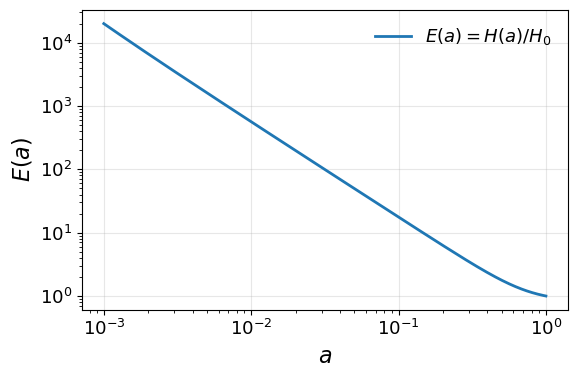

In [32]:
# LCDM
name = 'LCDM_Planck18_expansion.txt'
a_LCDM,E_LCDM,_ = load_frontend_exp(name)
plot_exp(a_LCDM,E_LCDM)

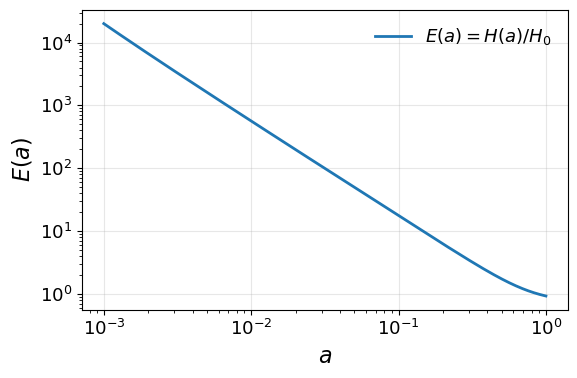

In [33]:
# nDGP
name = 'nDGP_Planck18_expansion_1.txt'
a_nDGP,E_nDGP,_ = load_frontend_exp(name)
plot_exp(a_nDGP,E_nDGP)

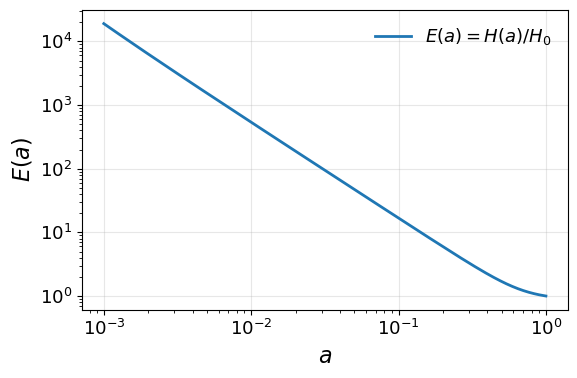

In [34]:
# cuGal
name = 'cuGal_f0p2_14dp_WMAP_expansion.txt'
# name = 'cuGal_f0p8_14dp_WMAP_expansion.txt'
a_cuGal,E_cuGal,_ = load_frontend_exp(name)
plot_exp(a_cuGal,E_cuGal)

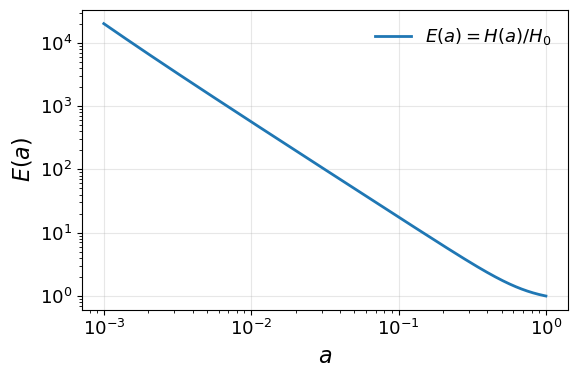

In [35]:
# Planck18
z_LCDM = 1/a_LCDM -1
H_Planck18 = cosmo.H(z_LCDM)
E_Planck18 = H_Planck18/H_Planck18[-1]
plot_exp(a_LCDM,E_Planck18)

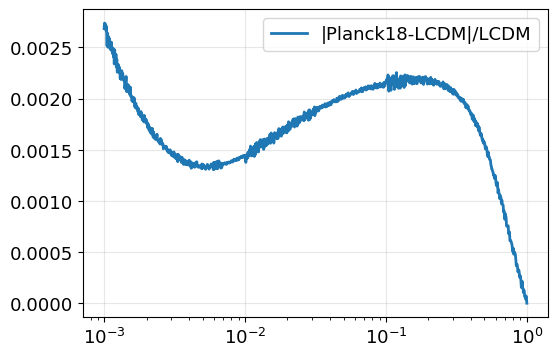

In [36]:
# LCDM vs Planck18
plt.plot(a_LCDM, np.abs(E_Planck18 - E_LCDM)/E_LCDM, label='|Planck18-LCDM|/LCDM')
plt.xscale('log')
plt.legend()

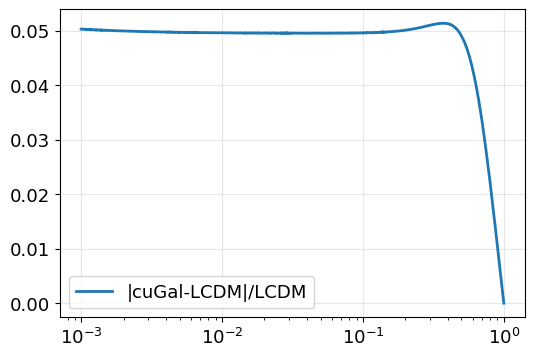

In [37]:
# LCDM vs cuGal
plt.plot(a_LCDM, np.abs(E_cuGal - E_LCDM)/E_LCDM, label='|cuGal-LCDM|/LCDM')
plt.xscale('log')
plt.legend()

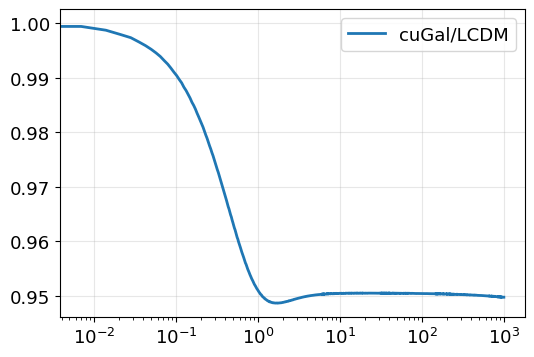

In [38]:
# LCDM vs cuGal
plt.plot(-1 + 1/a_LCDM, E_cuGal/E_LCDM, label='cuGal/LCDM')
plt.xscale('log')
plt.legend()

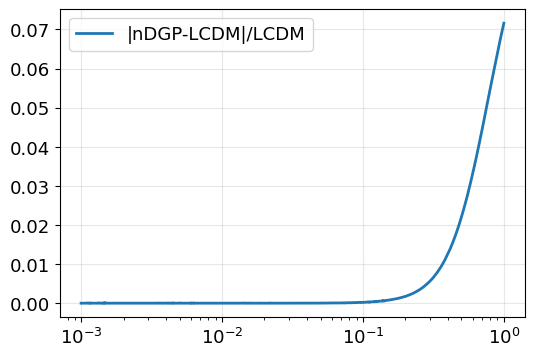

In [39]:
# LCDM vs nDGP
plt.plot(a_LCDM, np.abs(E_nDGP - E_LCDM)/E_LCDM, label='|nDGP-LCDM|/LCDM')
plt.xscale('log')
plt.legend()

In [40]:
def load_frontend_force(name):
    path = str(hp.OUTPUT_DIR) + '/'
    file_exp = path + name
    
    force = pd.read_csv(file_exp,
        sep=r"\s+",
        comment="#",
        names=["a", "Chi/delta_m", "beta"])
    
    a = force['a'].to_numpy()
    Chi_over_delta_m = force['Chi/delta_m'].to_numpy()
    beta = force['beta'].to_numpy()

    return a,Chi_over_delta_m,beta

In [43]:
aa_LCDM, Chi_LCDM, beta_LCDM = load_frontend_force('LCDM_Planck18_force.txt')
aa_cuGal, Chi_cuGal, beta_cuGal = load_frontend_force('cuGal_f0p2_14dp_WMAP_force.txt')
aa_nDGP, Chi_nDGP, beta_nDGP = load_frontend_force('nDGP_Planck18_force_1.txt')

In [44]:
zz_LCDM = 1/aa_LCDM - 1
zz_cuGal = 1/aa_cuGal - 1
zz_nDGP = 1/aa_nDGP - 1

In [45]:
def S(a,Chi_over_delta_m,delta_m):
    Chi = Chi_over_delta_m * delta_m
    Chi += 1e-10
    return (2/Chi) * (np.sqrt(1 + Chi) - 1)

In [46]:
#S_LCDM_1 = S(aa_LCDM, Chi_LCDM, delta_m=1)
#S_LCDM_m3 = S(aa_LCDM, Chi_LCDM, delta_m=1e-3)
#S_LCDM_p3 = S(aa_LCDM, Chi_LCDM, delta_m=1e3)
S_cuGal_1 = S(aa_cuGal, Chi_cuGal, delta_m=1)
S_cuGal_m3 = S(aa_cuGal, Chi_cuGal, delta_m=1e-3)
S_cuGal_p3 = S(aa_cuGal, Chi_cuGal, delta_m=1e3)
S_nDGP_1 = S(aa_nDGP, Chi_nDGP, delta_m=1)
S_nDGP_m3 = S(aa_nDGP, Chi_nDGP, delta_m=1e-3)
S_nDGP_p3 = S(aa_nDGP, Chi_nDGP, delta_m=1e3)

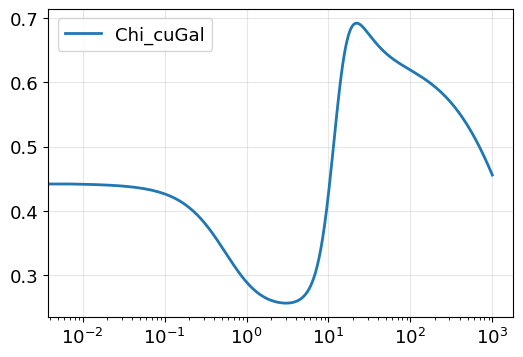

In [47]:
plt.plot(zz_cuGal, Chi_cuGal, label='Chi_cuGal')
plt.xscale('log')
plt.legend()

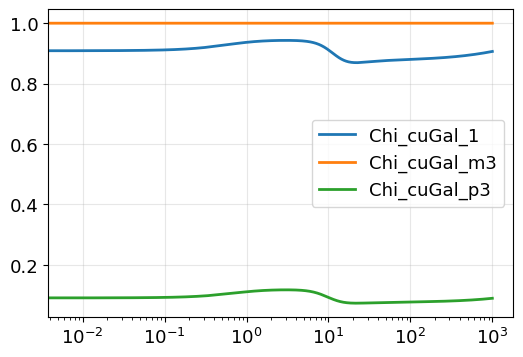

In [48]:
plt.plot(zz_cuGal, S_cuGal_1, label='Chi_cuGal_1')
plt.plot(zz_cuGal, S_cuGal_m3, label='Chi_cuGal_m3')
plt.plot(zz_cuGal, S_cuGal_p3, label='Chi_cuGal_p3')
plt.xscale('log')
plt.legend()

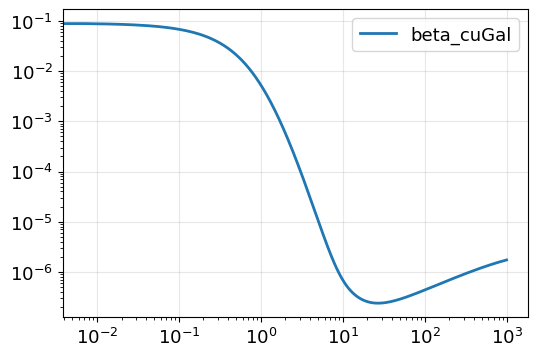

In [49]:
plt.plot(zz_cuGal, beta_cuGal, label='beta_cuGal')
plt.xscale('log')
plt.yscale('log')
plt.legend()

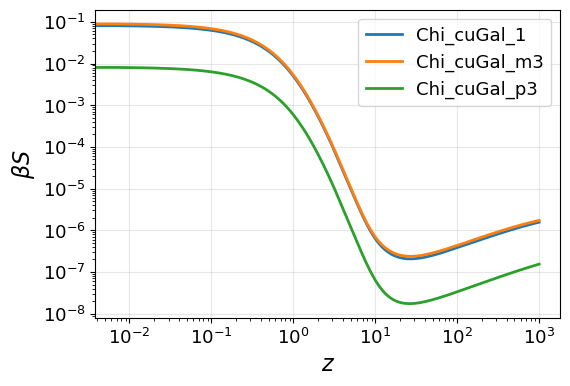

In [24]:
plt.plot(zz_cuGal, S_cuGal_1*beta_cuGal, label='Chi_cuGal_1')
plt.plot(zz_cuGal, S_cuGal_m3*beta_cuGal, label='Chi_cuGal_m3')
plt.plot(zz_cuGal, S_cuGal_p3*beta_cuGal, label='Chi_cuGal_p3')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$z$')
plt.ylabel(r'$\beta S$')
plt.legend()

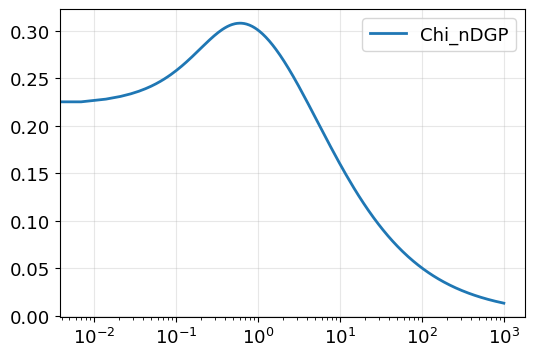

In [25]:
plt.plot(zz_nDGP, Chi_nDGP, label='Chi_nDGP')
plt.xscale('log')
plt.legend()

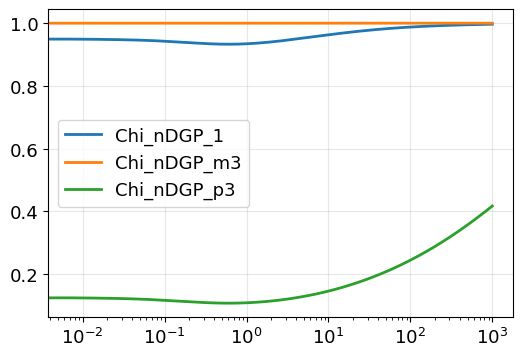

In [26]:
plt.plot(zz_nDGP, S_nDGP_1, label='Chi_nDGP_1')
plt.plot(zz_nDGP, S_nDGP_m3, label='Chi_nDGP_m3')
plt.plot(zz_nDGP, S_nDGP_p3, label='Chi_nDGP_p3')
plt.xscale('log')
plt.legend()

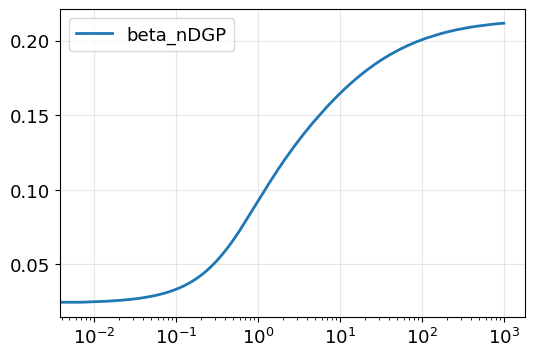

In [27]:
plt.plot(zz_nDGP, beta_nDGP, label='beta_nDGP')
plt.xscale('log')
plt.legend()

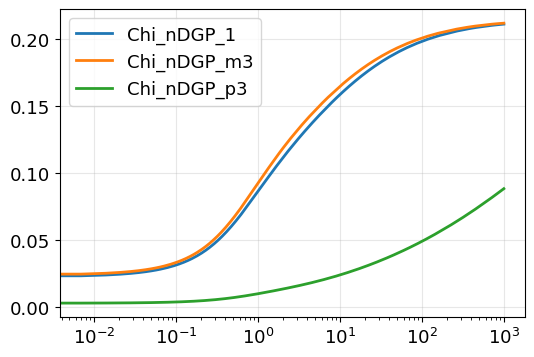

In [28]:
plt.plot(zz_nDGP, S_nDGP_1*beta_nDGP, label='Chi_nDGP_1')
plt.plot(zz_nDGP, S_nDGP_m3*beta_nDGP, label='Chi_nDGP_m3')
plt.plot(zz_nDGP, S_nDGP_p3*beta_nDGP, label='Chi_nDGP_p3')
plt.xscale('log')
plt.legend()